# Grid Resilience: 15-Minute Solar Ramp Forecasting on IBM LinuxONE
**IBM Z Datathon 2026 · Wildcard track · Event code SSF2026**

Texas (ERCOT) solar output can fall by thousands of megawatts within minutes, during the evening ramp-down and when clouds pass over solar regions. This notebook trains a model on IBM LinuxONE that forecasts statewide solar output **15 minutes ahead** and raises **ramp-down alerts**, giving operators time to dispatch battery storage toward hospitals and communities with electricity-dependent residents.

**Data:** ERCOT Fuel Mix Report (15-minute solar generation, April–September 2026) and Open-Meteo weather averaged over five Texas solar regions.

**Approach**
1. Verify the runtime platform (IBM Z, `s390x`).
2. Build a past-only clear-sky reference so the model can separate the normal daily solar curve from unexpected changes.
3. Forecast the next interval's solar output and compare against two baselines, separately for morning, midday, and evening.
4. Convert forecasts into ramp-down alerts, measure inference speed on LinuxONE, and export predictions and an ONNX model.

## 1. Runtime platform
Confirms the notebook is executing on IBM Z (`s390x` architecture) and records library versions for reproducibility.

In [1]:
import platform, sys, os, time
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

print("Machine architecture :", platform.machine())   # s390x = IBM Z
print("Operating system     :", platform.platform())
print("Python               :", sys.version.split()[0])
print("pandas               :", pd.__version__)
print("scikit-learn         :", sklearn.__version__)
print("CPU cores available  :", os.cpu_count())

Machine architecture : s390x
Operating system     : Linux-6.8.0-147-generic-s390x-with-glibc2.39
Python               : 3.12.15
pandas               : 3.0.6
scikit-learn         : 1.9.0
CPU cores available  : 3


## 2. Configuration
- **Training:** April–June 2026, **validation:** July (used only to tune the alert threshold), then the final model is refit on April–July.
- **Test:** August–September 2026, never seen during training or tuning.
- **Ramp-down event:** solar output falls by at least `RAMP_MW` within the next 15-minute interval.

In [2]:
DATA_FILE  = "shared/features.csv"     # engineered feature table
OUTPUT_DIR = "shared"                  # outputs are written here
os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_END  = pd.Timestamp("2026-07-01 05:00", tz="UTC")   # interval-end cutoff (midnight Texas time)
VALID_END  = pd.Timestamp("2026-08-01 05:00", tz="UTC")
STEP       = pd.Timedelta("15min")                        # forecast horizon = one interval
RAMP_MW    = 500                                          # ramp-down event size (MW in 15 min)
RANDOM_SEED = 42

## 3. Load data

In [3]:
assert os.path.exists(DATA_FILE), "features.csv not found in the shared folder"
df = pd.read_csv(DATA_FILE)
df["time_utc"] = pd.to_datetime(df["time_utc"], utc=True)
df = df.sort_values("time_utc").drop_duplicates("time_utc").reset_index(drop=True)

REQUIRED = ["time_utc", "solar_mw", "solar_lag15", "solar_lag30", "solar_lag60", "change_15",
            "hour_local", "day_of_year", "cloud_cover", "shortwave_radiation", "temperature_2m",
            "is_daylight", "target_solar_15"]
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"features.csv is missing columns: {missing}"

print("Rows        :", len(df))
print("Range (UTC) :", df["time_utc"].min(), "->", df["time_utc"].max())
print("Interval    :", df["time_utc"].diff().mode()[0])
print("Peak solar  :", f"{df['solar_mw'].max():,.0f} MW")
df.head()

Rows        : 17563
Range (UTC) : 2026-04-01 06:15:00+00:00 -> 2026-10-01 04:45:00+00:00
Interval    : 0 days 00:15:00
Peak solar  : 35,343 MW


,time_utc,solar_mw,solar_lag15,solar_lag30,solar_lag60,change_15,hour_local,day_of_year,cloud_cover,shortwave_radiation,temperature_2m,is_daylight,target_solar_15,target_drop
0,2026-04-01 06:15:00+00:00,0.001912,0.001976,0.002084,0.002016,-0.000064,1,91,58.4,0.0,21.84,0,0.001872,0
1,2026-04-01 06:30:00+00:00,0.001872,0.001912,0.001976,0.001976,-0.000040,1,91,58.4,0.0,21.84,0,0.001936,0
2,2026-04-01 06:45:00+00:00,0.001936,0.001872,0.001912,0.002084,0.000064,1,91,58.4,0.0,21.84,0,0.001880,0
3,2026-04-01 07:00:00+00:00,0.001880,0.001936,0.001872,0.001976,-0.000056,2,91,50.0,0.0,21.14,0,0.001976,0
4,2026-04-01 07:15:00+00:00,0.001976,0.001880,0.001936,0.001912,0.000096,2,91,50.0,0.0,21.14,0,0.001904,0


## 4. Why a fixed-percentage drop target does not work
A first version labeled a "drop" when output fell more than 20% within 15 minutes. Checking those labels by hour shows they are almost entirely the **normal evening sunset**, not unexpected events. Statewide solar is spread over a large area, so it rarely loses 20% in 15 minutes at midday.

In [4]:
old_drop = (df["target_solar_15"] < 0.8 * df["solar_mw"]) & (df["is_daylight"] == 1)
by_hour = old_drop.groupby(df["hour_local"]).sum()
print("20%-drop labels by local hour (daylight only):")
print(by_hour[by_hour > 0].to_string())
print(f"Share between 5 PM and 9 PM: {by_hour.loc[17:20].sum() / by_hour.sum():.1%}")

20%-drop labels by local hour (daylight only):
hour_local
17      2
18    146
19    565
20    148
Share between 5 PM and 9 PM: 100.0%


## 5. Clear-sky reference and features
For each 15-minute time of day, the **clear-sky reference** is the highest output seen at that time over the previous 14 days (past days only). The **clear-sky index** `kt = solar / clear-sky` measures how far today is below a clear day, which separates weather effects from the normal daily curve. All features use only information available at forecast time.

In [5]:
local = df["time_utc"].dt.tz_convert("America/Chicago")
df["slot"] = local.dt.hour * 4 + local.dt.minute // 15        # 15-minute slot of the day (0-95)
df["date"] = local.dt.date

grid = df.pivot_table(index="date", columns="slot", values="solar_mw")
clear = grid.shift(1).rolling(14, min_periods=5).max()          # previous days only
clear = clear.stack().rename("clear_sky_mw").reset_index()
df = df.merge(clear, on=["date", "slot"], how="left")

df["clear_sky_next"] = df["clear_sky_mw"].shift(-1)             # reference for the next slot (known in advance)
df["cs_change"]      = df["clear_sky_next"] - df["clear_sky_mw"]
df["kt"]             = df["solar_mw"]    / df["clear_sky_mw"].clip(lower=1)
df["kt_lag15"]       = df["solar_lag15"] / df["clear_sky_mw"].shift(1).clip(lower=1)
df["kt_lag30"]       = df["solar_lag30"] / df["clear_sky_mw"].shift(2).clip(lower=1)
df["change_30"]      = df["solar_mw"] - df["solar_lag30"]
df["change_60"]      = df["solar_mw"] - df["solar_lag60"]

df["target_change"]  = df["target_solar_15"] - df["solar_mw"]                    # what the model predicts
df["target_ramp"]    = (df["target_change"] <= -RAMP_MW).astype(int)            # ramp-down event label

FEATURES = ["solar_mw", "solar_lag15", "solar_lag30", "solar_lag60", "change_15", "change_30", "change_60",
            "hour_local", "slot", "day_of_year", "cloud_cover", "shortwave_radiation", "temperature_2m",
            "clear_sky_mw", "clear_sky_next", "cs_change", "kt", "kt_lag15", "kt_lag30"]
assert not any(f.startswith("target_") for f in FEATURES)

day = df[df["is_daylight"] == 1].dropna(subset=FEATURES + ["target_solar_15"]).copy()
print("Daylight rows with full features:", len(day))

Daylight rows with full features: 8843


## 6. Time-based split with boundary purge
Splits are chronological. At each boundary, rows whose 15-minute-ahead target falls in the next split are removed, so no future information leaks into training or tuning.

In [6]:
t = day["time_utc"]
train = day[t + STEP < TRAIN_END]
valid = day[(t >= TRAIN_END) & (t + STEP < VALID_END)]
full  = day[t + STEP < VALID_END]                  # April-July, for the final model
test  = day[t >= VALID_END]

for name, part in [("Train", train), ("Validation", valid), ("Final train", full), ("Test", test)]:
    print(f"{name:12s}: {len(part):5,} rows  {part['time_utc'].min().date()} to {part['time_utc'].max().date()}"
          f"  ramp events: {int(part['target_ramp'].sum())}")

Train       : 4,307 rows  2026-04-06 to 2026-07-01  ramp events: 1309
Validation  : 1,615 rows  2026-07-01 to 2026-08-01  ramp events: 486
Final train : 5,922 rows  2026-04-06 to 2026-08-01  ramp events: 1795
Test        : 2,921 rows  2026-08-01 to 2026-09-30  ramp events: 921


## 7. Baselines
- **Persistence:** output in 15 minutes equals output now.
- **Smart persistence:** the clear-sky index stays the same, so output follows the clear-sky curve. This is the standard, much stronger baseline in solar forecasting and already captures the normal sunset shape.

In [7]:
def add_baselines(part):
    part = part.copy()
    part["persistence"]       = part["solar_mw"]
    part["smart_persistence"] = part["kt"].clip(0, 1.5) * part["clear_sky_next"]
    return part
train, valid, full, test = [add_baselines(p) for p in (train, valid, full, test)]

## 8. Model training on LinuxONE
A histogram-based gradient-boosting regressor (scikit-learn) predicts the **change** in output over the next 15 minutes. The ramp alert threshold is tuned on July only, then the final model is refit on April–July.

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, precision_score, recall_score, f1_score

def fit(part):
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=RANDOM_SEED)
    return m.fit(part[FEATURES], part["target_change"])

t0 = time.time()
tune_model = fit(train)
valid_change = tune_model.predict(valid[FEATURES])
candidates = np.arange(200, 801, 50)
valid_f1 = [f1_score(valid["target_ramp"], (valid_change <= -c).astype(int), zero_division=0) for c in candidates]
ALERT_MW = float(candidates[int(np.argmax(valid_f1))])

model = fit(full)
train_seconds = time.time() - t0
print(f"Alert threshold (tuned on July): predicted drop >= {ALERT_MW:.0f} MW")
print(f"Training time on {platform.machine()}: {train_seconds:.1f} seconds")

Alert threshold (tuned on July): predicted drop >= 400 MW
Training time on s390x: 6.9 seconds


## 9. Forecast accuracy on August–September (test)
Mean absolute error (MW) by time of day. **Skill** is the reduction in error versus each baseline (higher is better).

In [9]:
test = test.copy()
test["predicted_change"]   = model.predict(test[FEATURES])
test["predicted_solar_15"] = test["solar_mw"] + test["predicted_change"]

periods = {"All daylight": test["hour_local"] >= 0,
           "Morning (before 10)": test["hour_local"] < 10,
           "Midday (10-16)": (test["hour_local"] >= 10) & (test["hour_local"] < 16),
           "Evening (17-20)": (test["hour_local"] >= 17) & (test["hour_local"] <= 20)}
rows = []
for name, mask in periods.items():
    p = test[mask]
    mae = {k: mean_absolute_error(p["target_solar_15"], p[c])
           for k, c in [("persistence", "persistence"), ("smart", "smart_persistence"), ("model", "predicted_solar_15")]}
    rows.append({"period": name, "rows": len(p),
                 "MAE persistence": round(mae["persistence"]), "MAE smart persistence": round(mae["smart"]),
                 "MAE model": round(mae["model"]),
                 "skill vs persistence": f"{1 - mae['model'] / mae['persistence']:.1%}",
                 "skill vs smart persistence": f"{1 - mae['model'] / mae['smart']:.1%}"})
accuracy = pd.DataFrame(rows).set_index("period")
accuracy

,rows,MAE persistence,MAE smart persistence,MAE model,skill vs persistence,skill vs smart persistence
period,,,,,,
All daylight,2921,1282,465,331,74.2%,28.9%
Morning (before 10),529,2919,674,320,89.0%,52.5%
Midday (10-16),1464,360,326,290,19.6%,11.2%
Evening (17-20),684,2255,620,426,81.1%,31.3%


## 10. Ramp-down alerts
An alert fires when the forecast drop is at least the tuned threshold. The baseline alert fires when output already fell by at least `RAMP_MW` in the last 15 minutes.

In [10]:
test["ramp_alert"]    = (test["predicted_change"] <= -ALERT_MW).astype(int)
test["baseline_alert"] = (test["change_15"] <= -RAMP_MW).astype(int)

def alert_scores(p, col):
    y = p["target_ramp"]
    return {"events": int(y.sum()), "alerts": int(p[col].sum()),
            "precision": round(precision_score(y, p[col], zero_division=0), 2),
            "recall": round(recall_score(y, p[col], zero_division=0), 2),
            "f1": round(f1_score(y, p[col], zero_division=0), 2)}

rows = []
for name in ["All daylight", "Midday (10-16)", "Evening (17-20)"]:
    p = test[periods[name]]
    rows.append({"period": name, "method": "Baseline rule", **alert_scores(p, "baseline_alert")})
    rows.append({"period": name, "method": "AI model", **alert_scores(p, "ramp_alert")})
alerts = pd.DataFrame(rows).set_index(["period", "method"])
alerts

events  alerts  precision  recall    f1
period          method                                                
All daylight    Baseline rule     921     860       0.78    0.73  0.76
                AI model          921     837       0.86    0.78  0.82
Midday (10-16)  Baseline rule     179     155       0.30    0.26  0.28
                AI model          179      41       0.49    0.11  0.18
Evening (17-20) Baseline rule     638     608       0.96    0.91  0.93
                AI model          638     680       0.93    0.99  0.96

## 11. Inference speed on LinuxONE
Latency for single forecasts (as in a live 15-minute alert loop) and throughput for batch scoring.

In [11]:
rows_sample = test[FEATURES].sample(n=min(1000, len(test)), random_state=RANDOM_SEED)
model.predict(rows_sample.iloc[[0]])                     # warm-up

t0 = time.perf_counter()
for i in range(len(rows_sample)):
    model.predict(rows_sample.iloc[[i]])
single_ms = (time.perf_counter() - t0) / len(rows_sample) * 1000

t0 = time.perf_counter()
model.predict(test[FEATURES])
batch_ms = (time.perf_counter() - t0) * 1000

print(f"Platform                : {platform.machine()}")
print(f"One forecast            : {single_ms:.2f} ms")
print(f"Whole test set ({len(test):,} rows): {batch_ms:.0f} ms total, {batch_ms / len(test) * 1000:.1f} microseconds per row")

Platform                : s390x
One forecast            : 19.25 ms
Whole test set (2,921 rows): 35 ms total, 12.0 microseconds per row


## 12. Export predictions
Writes test-period forecasts and alerts to `predictions.csv`, which feeds the battery-dispatch recommendation layer and the demo.

In [12]:
pred = pd.DataFrame({
    "time_utc":           test["time_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ").values,
    "solar_mw":           test["solar_mw"].round(1).values,
    "target_solar_15":    test["target_solar_15"].round(1).values,
    "predicted_solar_15": test["predicted_solar_15"].round(1).values,
    "predicted_change_mw": test["predicted_change"].round(1).values,
    "target_drop":        test["target_ramp"].values,      # actual ramp-down >= RAMP_MW
    "predicted_drop":     test["ramp_alert"].values,       # model alert
})
pred.to_csv(os.path.join(OUTPUT_DIR, "predictions.csv"), index=False)
accuracy.to_csv(os.path.join(OUTPUT_DIR, "results_accuracy.csv"))
alerts.to_csv(os.path.join(OUTPUT_DIR, "results_alerts.csv"))
print("Saved: shared/predictions.csv -", len(pred), "rows")
pred.head()

Saved: shared/predictions.csv - 2921 rows


,time_utc,solar_mw,target_solar_15,predicted_solar_15,predicted_change_mw,target_drop,predicted_drop
0,2026-08-01T12:30:00Z,2047.3,4146.5,4489.2,2441.8,0,0
1,2026-08-01T12:45:00Z,4146.5,7010.9,6977.4,2830.9,0,0
2,2026-08-01T13:00:00Z,7010.9,9969.8,10327.2,3316.2,0,0
3,2026-08-01T13:15:00Z,9969.8,13265.6,12999.7,3029.9,0,0
4,2026-08-01T13:30:00Z,13265.6,16224.7,16322.0,3056.5,0,0


## 13. Demo day selection
Test days where the model caught the most ramp-down events, plus the best day with a midday (cloud-driven) event.

In [13]:
test["day"]    = test["time_utc"].dt.tz_convert("America/Chicago").dt.date
test["caught"] = (test["ramp_alert"] == 1) & (test["target_ramp"] == 1)
by_day = test.groupby("day").agg(ramp_events=("target_ramp", "sum"), caught=("caught", "sum"))
best_days = by_day.sort_values(["caught", "ramp_events"], ascending=False).head(3)
print("Best demo days (Texas date):"); print(best_days)

mid = test[periods["Midday (10-16)"]]
mid_days = mid.groupby("day").agg(ramp_events=("target_ramp", "sum"), caught=("caught", "sum"))
mid_days = mid_days[mid_days["ramp_events"] > 0].sort_values(["caught", "ramp_events"], ascending=False)
print("\nBest midday (cloud) demo days:"); print(mid_days.head(3))

Best demo days (Texas date):
            ramp_events  caught
day                            
2026-09-10           21      16
2026-09-19           18      16
2026-08-01           18      14

Best midday (cloud) demo days:
            ramp_events  caught
day                            
2026-09-10            8       3
2026-09-24            8       3
2026-09-19            5       3


## 14. Demo day visualization
Actual output, the 15-minute-ahead forecast, and model alerts. Alerts appear one interval before each large drop.

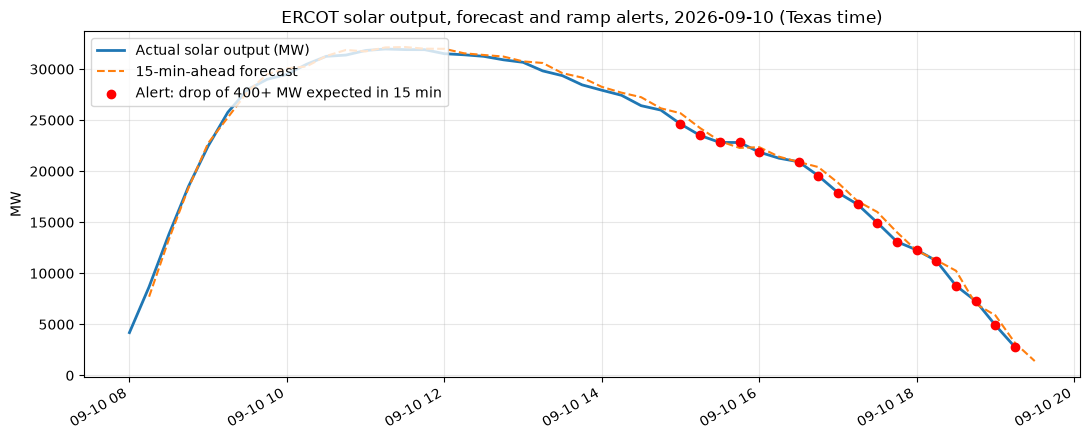

In [14]:
demo_day = best_days.index[0]
d = test[test["day"] == demo_day]
lt = d["time_utc"].dt.tz_convert("America/Chicago")
fc_time = lt + STEP                                       # forecast is for 15 minutes later

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(lt, d["solar_mw"], color="#1f77b4", lw=2, label="Actual solar output (MW)")
ax.plot(fc_time, d["predicted_solar_15"], color="#ff7f0e", ls="--", label="15-min-ahead forecast")
a = d[d["ramp_alert"] == 1]
ax.scatter(a["time_utc"].dt.tz_convert("America/Chicago"), a["solar_mw"], color="red", zorder=3,
           label=f"Alert: drop of {ALERT_MW:.0f}+ MW expected in 15 min")
ax.set_title(f"ERCOT solar output, forecast and ramp alerts, {demo_day} (Texas time)")
ax.set_ylabel("MW"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "demo_day_preview.png"), dpi=150)
plt.show()

## 15. Model export
Saves the trained model with joblib and exports it to **ONNX**, a portable format supported by IBM Z AI tooling (e.g., the IBM Z Deep Learning Compiler) for accelerated inference on the Telum on-chip AI accelerator.

In [15]:
import joblib
joblib.dump({"model": model, "features": FEATURES, "alert_mw": ALERT_MW, "ramp_mw": RAMP_MW},
            os.path.join(OUTPUT_DIR, "ramp_model.joblib"))
print("Saved model: shared/ramp_model.joblib")
try:
    from skl2onnx import convert_sklearn
    from skl2onnx.common.data_types import FloatTensorType
    onx = convert_sklearn(model, initial_types=[("input", FloatTensorType([None, len(FEATURES)]))])
    with open(os.path.join(OUTPUT_DIR, "ramp_model.onnx"), "wb") as f:
        f.write(onx.SerializeToString())
    print("Saved ONNX model: shared/ramp_model.onnx")
except Exception as e:
    print("ONNX export skipped:", type(e).__name__, "-", str(e)[:120])

Saved model: shared/ramp_model.joblib
Saved ONNX model: shared/ramp_model.onnx


## Results summary

In [16]:
a_all = accuracy.loc["All daylight"]; a_mid = accuracy.loc["Midday (10-16)"]; a_eve = accuracy.loc["Evening (17-20)"]
r_ai = alerts.loc[("All daylight", "AI model")]; r_bl = alerts.loc[("All daylight", "Baseline rule")]
print("=" * 66)
print("GRID RESILIENCE - RESULTS ON", platform.machine().upper())
print("=" * 66)
print(f"Data            : ERCOT 15-min solar, test {test['time_utc'].min().date()} to {test['time_utc'].max().date()}")
print(f"Forecast error  : {a_all['MAE model']:,} MW (persistence {a_all['MAE persistence']:,}, smart persistence {a_all['MAE smart persistence']:,})")
print(f"Skill vs smart persistence: all {a_all['skill vs smart persistence']}, midday {a_mid['skill vs smart persistence']}, evening {a_eve['skill vs smart persistence']}")
print(f"Ramp alerts ({RAMP_MW}+ MW): AI F1 {r_ai['f1']} (precision {r_ai['precision']}, recall {r_ai['recall']})"
      f" vs baseline F1 {r_bl['f1']}")
print(f"Speed           : {single_ms:.2f} ms per forecast; {batch_ms / len(test) * 1000:.1f} microseconds per row in batch, on {platform.machine()}")

GRID RESILIENCE - RESULTS ON S390X
Data            : ERCOT 15-min solar, test 2026-08-01 to 2026-09-30
Forecast error  : 331 MW (persistence 1,282, smart persistence 465)
Skill vs smart persistence: all 28.9%, midday 11.2%, evening 31.3%
Ramp alerts (500+ MW): AI F1 0.82 (precision 0.86, recall 0.78) vs baseline F1 0.76
Speed           : 19.25 ms per forecast; 12.0 microseconds per row in batch, on s390x
